# Relative Value in Economically Related Securities
**MRP Initial Submission** · Ben Pinoli, Will Van De Graaff, Josh Barker, Kai Sandberg · November 6, 2026

## At a glance

We ask whether price gaps between economically related securities can be explained by identifiable factors, and whether those gaps could have been traded using information available at the time. Our deepest case is the Samsung Electronics common/preferred pair, supported by a broader screen of 114 related-security records.

**What we found**

- **The gap is not just share supply.** Samsung's issued share counts stayed constant across years in which the preferred discount moved materially, and a simple "persistence" forecast beat a trailing five-year median at two- and five-year horizons.
- **Common movement, unclear cause.** Preferred discounts across Korean issuers tend to widen and narrow together (all 16 eligible peers narrowed in 2013 to 2014).
- **Daily US factor returns explain very little.** Adjusted R² never exceeds about 3.5%. Of 44 factor tests, 6 look significant before adjustment and none survives multiple-testing correction at 5% in the main sample.
- **The discount mean-reverts, mostly slowly.** Its implied half-life is about 75 to 160 trading sessions in most windows, but only about 12 sessions in 2015 to 2019.

**What we do not yet have.** A validated fair-discount model or trading strategy. We therefore report **no portfolio returns, Sharpe ratios, or drawdowns**: any such figure would have to be invented. Section 5 explains the gap and lays out how we will close it.

| Requirement | Where | Status |
|---|---|---|
| Method of processing data | Section 2 | Documented |
| Evaluation of signal effectiveness | Section 4 | Retrospective explanatory tests and benchmarks; no out-of-sample signal yet |
| Portfolio performance, risk and return | Section 5 | Not available; pipeline and protocol described |
| Primary visuals | Figures 1 to 7 | Included; all drawn from numbers we actually have |

## 1. Research question

We separate three questions that are easy to blur together: **(1) Measurement**: what price difference exists? **(2) Explanation**: what drives it? **(3) Application**: could it have been identified and traded with information available at the time? A price gap is not mispricing, and mispricing is not an executable trade, so we avoid the word "arbitrage" until execution constraints are established.

## 2. Data and method of processing

**Outcomes.** For Samsung common and preferred prices we construct the *discount* as `100 × (1 − preferred / common)`, in percentage points.

| Variable | Definition |
|---|---|
| `dd_pp` | Daily change in the discount (percentage points) |
| `dg` | Daily change in `log(common / preferred)` |
| `lag_discount` | Prior-session discount level |
| `lag_activity` | Prior-session `log(preferred volume / common volume)`, in shares traded |

**Explanatory data.** Eleven vendor US factor returns (family `USSLOWL`): COUNTRY, BETA, VALUE, SIZE, MOMENTUM, LIQUIDTY, RESVOL, LEVERAGE, DIVYILD, PROFIT, SEMICOND. Returns are converted from percent to decimals and aligned to the Korean session using a *retrospective preceding-US-session rule*. We do not interpret COUNTRY as a market return.

**Specifications.** B01 regresses `dd_pp` on the factors; B02 does the same for `dg`; B03 adds `lag_discount`; B04 adds `lag_activity`. Each runs on a *main* sample and a *sensitivity* sample that masks registered review-flagged dates, over the full period and three windows (2005 to 2014, 2015 to 2019, 2020 to 2026). Standard errors are Newey-West (bandwidth 20), and p-values are adjusted across tests with the Benjamini-Hochberg (BH) procedure to give q-values. These are **retrospective explanatory sensitivities, not point-in-time forecasts.**

**Data quality.** We preserved source defects rather than repairing them after seeing results: incompatible historical split scales for one issuer were quarantined, a header-only Korean data response was not turned into prices, converted and unlisted counterparts were separated from live pairs, and source access restrictions were respected. Original files, frozen protocols, and output hashes are retained.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from scipy.stats import norm

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
NAVY, TEAL, GOLD, GRAY, RED = "#1f3a5f", "#2a9d8f", "#e9a23b", "#8d99ae", "#c0392b"
WINDOWS = ["Full", "2005-14", "2015-19", "2020-26"]

## 3. Context: Samsung's structure and Korean peers

Three structural points shape how we model Samsung. First, **share supply** was constant while the discount moved, which weakens the simplest supply story (though issued shares are not free float, so liquidity effects remain open). Second, **persistence is a serious benchmark**: it beat a trailing five-year median at two- and five-year horizons, although this does not show the discount is permanently stable or that history is fair value. Third, the two classes have **different holders**: foreign investors own about 73% of the preferred class versus 46% of the common, so FX and investor-type hypotheses stay on the list.

Across Korean preferred shares, discounts move together: all 16 eligible non-Samsung issuers narrowed in 2013 to 2014, and 14 of 20 and 16 of 22 moved with later narrowing and widening episodes. This is common movement in a selected universe; it does not identify a cause.

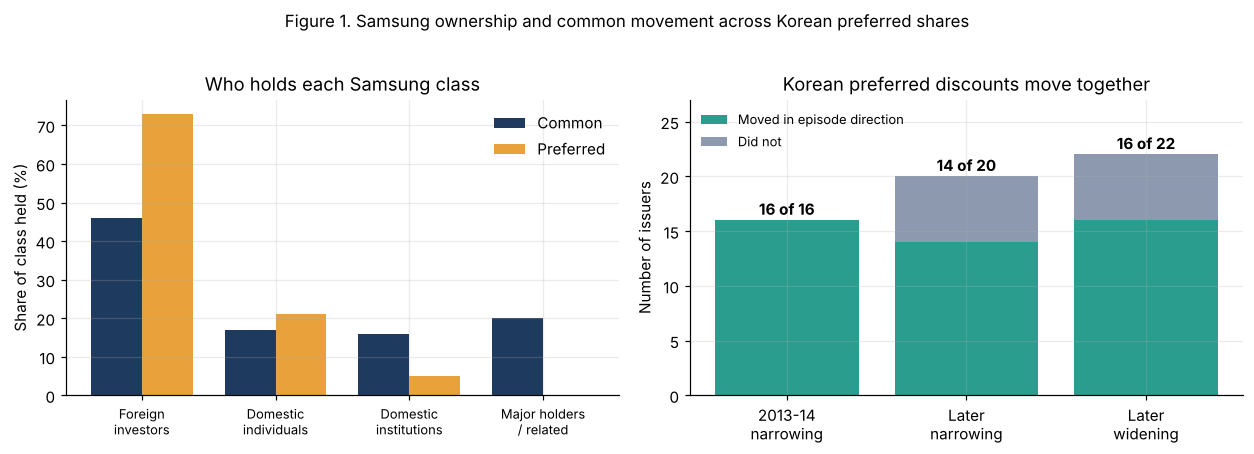

In [2]:
holders = pd.DataFrame({"Group": ["Foreign\ninvestors", "Domestic\nindividuals", "Domestic\ninstitutions", "Major holders\n/ related"],
                        "Common": [46, 17, 16, 20], "Preferred": [73, 21, 5, 0.1]})
eps = pd.DataFrame({"Episode": ["2013-14\nnarrowing", "Later\nnarrowing", "Later\nwidening"],
                    "Moved": [16, 14, 16], "Eligible": [16, 20, 22]})
eps["Did not"] = eps.Eligible - eps.Moved

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4))
x = np.arange(4); w = 0.38
a1.bar(x - w/2, holders.Common, w, color=NAVY, label="Common")
a1.bar(x + w/2, holders.Preferred, w, color=GOLD, label="Preferred")
a1.set_xticks(x); a1.set_xticklabels(holders.Group, fontsize=8.5)
a1.set_ylabel("Share of class held (%)"); a1.set_title("Who holds each Samsung class"); a1.legend(frameon=False)

a2.bar(eps.Episode, eps.Moved, color=TEAL, label="Moved in episode direction")
a2.bar(eps.Episode, eps["Did not"], bottom=eps.Moved, color=GRAY, label="Did not")
for i, r in eps.iterrows():
    a2.text(i, r.Eligible + 0.5, f"{r.Moved} of {r.Eligible}", ha="center", fontweight="bold")
a2.set_ylim(0, 27); a2.set_ylabel("Number of issuers")
a2.set_title("Korean preferred discounts move together"); a2.legend(loc="upper left", frameon=False, fontsize=8.5)
fig.suptitle("Figure 1. Samsung ownership and common movement across Korean preferred shares", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

*Ownership figures are point-in-time stocks from team notes, not flows. Peer denominators differ by episode, so the bars are not one balanced panel.*

## 4. Signal effectiveness

### 4.1 Do US factor returns explain daily changes in the discount?

Mostly no. Figure 2 shows the t-statistic for every factor in every window (B01, main sample). Only a handful of cells exceed conventional significance, and **7 of 11 factors change sign at least once across windows**, which is a warning against a stable relationship. A positive BETA effect appears in the full sample and 2020 to 2026, MOMENTUM is positive only in 2020 to 2026, and DIVYILD is positive in the full sample and 2020 to 2026. For scale, the 2020 to 2026 MOMENTUM coefficient of 13.5 means a 1% factor return is associated with about 0.13 percentage points of daily discount change.

Factors whose coefficient changes sign at least once across windows: 7 of 11


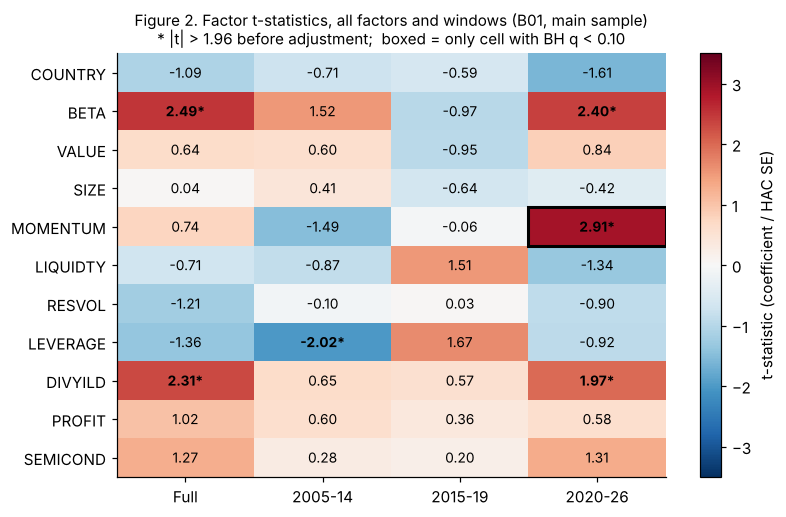

In [3]:
# B01 main sample: (coefficient, HAC SE, BH q) for Full, 2005-14, 2015-19, 2020-26 (Nov 2 regression tables)
B01 = {
 "COUNTRY":  [(-2.1935, 2.0178, .6278), (-3.1894, 4.4839, .7488), (-2.6882, 4.5949, .7915), (-3.2004, 1.9897, .4309)],
 "BETA":     [(13.6373, 5.4778, .1416), (21.4721, 14.1068, .4676), (-15.1601, 15.6918, .6713), (12.9875, 5.4105, .1502)],
 "VALUE":    [(7.2575, 11.2597, .7678), (12.8799, 21.6288, .7896), (-27.0367, 28.3539, .6713), (11.2862, 13.4498, .7119)],
 "SIZE":     [(0.2610, 6.4666, .9943), (4.0785, 9.8407, .8431), (-11.9872, 18.6684, .7678), (-3.9537, 9.4492, .8431)],
 "MOMENTUM": [(3.4843, 4.7172, .7454), (-19.8839, 13.3734, .4855), (-0.7247, 11.8629, .9845), (13.4827, 4.6284, .0612)],
 "LIQUIDTY": [(-7.9717, 11.2348, .7488), (-17.4859, 20.0978, .6969), (42.6724, 28.3099, .4762), (-19.9681, 14.9398, .5167)],
 "RESVOL":   [(-8.7093, 7.1814, .5643), (-1.7134, 17.6219, .9716), (0.5635, 16.6803, .9943), (-7.4033, 8.2120, .6860)],
 "LEVERAGE": [(-17.4532, 12.7880, .5156), (-45.8566, 22.7377, .2555), (49.5145, 29.7195, .4262), (-16.5572, 17.9565, .6770)],
 "DIVYILD":  [(26.2953, 11.4009, .1762), (16.9503, 26.2052, .7678), (15.9370, 28.1494, .7970), (26.5597, 13.4744, .2707)],
 "PROFIT":   [(12.5697, 12.2996, .6604), (13.6137, 22.6593, .7877), (14.1356, 39.4527, .8566), (8.1967, 14.1389, .7932)],
 "SEMICOND": [(1.7514, 1.3761, .5304), (0.6100, 2.1934, .8881), (0.7120, 3.4768, .9192), (2.7083, 2.0732, .5233)],
}
facs = list(B01)
T = np.array([[c / s for c, s, q in B01[f]] for f in facs])

fig, ax = plt.subplots(figsize=(7.5, 4.8))
im = ax.imshow(T, cmap="RdBu_r", vmin=-3.5, vmax=3.5, aspect="auto"); ax.grid(False)
ax.set_xticks(range(4)); ax.set_xticklabels(WINDOWS); ax.set_yticks(range(len(facs))); ax.set_yticklabels(facs)
for i in range(len(facs)):
    for j in range(4):
        big = abs(T[i, j]) > 1.96
        ax.text(j, i, f"{T[i,j]:.2f}" + ("*" if big else ""), ha="center", va="center", fontsize=9, fontweight="bold" if big else "normal")
mi = facs.index("MOMENTUM")
ax.add_patch(Rectangle((2.5, mi - 0.5), 1, 1, fill=False, ec="black", lw=2))
fig.colorbar(im, ax=ax).set_label("t-statistic (coefficient / HAC SE)")
ax.set_title("Figure 2. Factor t-statistics, all factors and windows (B01, main sample)\n* |t| > 1.96 before adjustment;  boxed = only cell with BH q < 0.10", fontsize=10)
plt.tight_layout(); plt.show()
sign_flips = sum(abs(np.sign(r).sum()) < 4 for r in T)
print(f"Factors whose coefficient changes sign at least once across windows: {sign_flips} of {len(facs)}")

### 4.2 How much survives multiple-testing correction, and how much variance is explained?

Testing 44 coefficients invites false positives: about two would look significant by chance at the 5% level, and we see six. After BH adjustment, **none** clears 5% in the main sample, and only MOMENTUM in 2020 to 2026 (q = 0.061) falls below 10%. The strongest survivors are BETA in the full-window *sensitivity* samples (q = 0.046 in B01, 0.041 in B02), where flagged dates are masked. Explanatory power is tiny throughout (Figure 3, right). The largest values, around 3.3% in 2015 to 2019, appear only when `lag_discount` is added, which reflects the discount's own mean reversion rather than a factor effect.

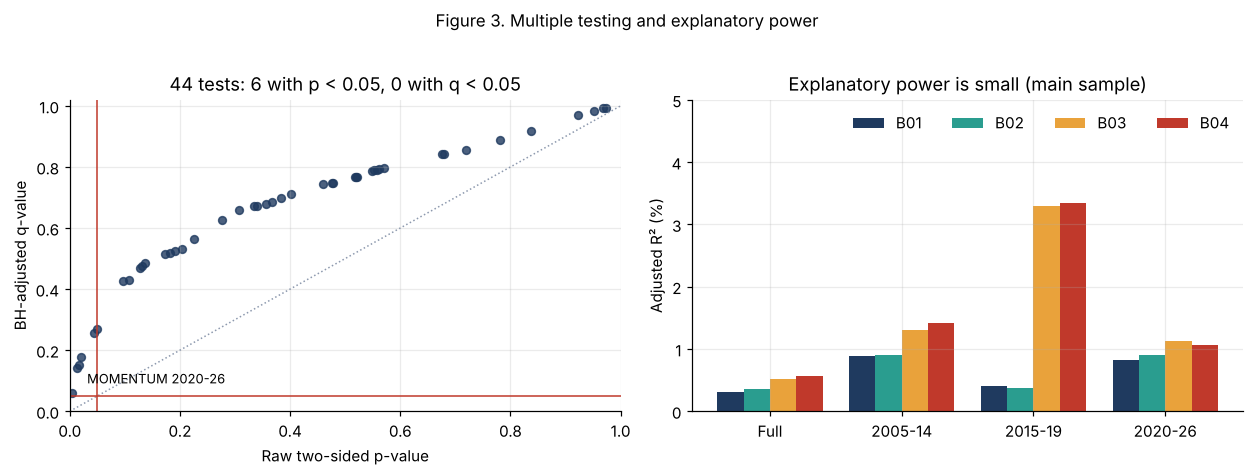

In [4]:
rows = [(f, w, 2 * (1 - norm.cdf(abs(c / s))), q) for f in facs for w, (c, s, q) in zip(WINDOWS, B01[f])]
pq = pd.DataFrame(rows, columns=["factor", "window", "p", "q"])
n_raw, n_q05, n_q10 = int((pq.p < .05).sum()), int((pq.q < .05).sum()), int((pq.q < .10).sum())

adj_r2 = pd.DataFrame({"B01": [.0031, .0089, .0040, .0082], "B02": [.0035, .0091, .0037, .0090],
                       "B03": [.0051, .0131, .0330, .0112], "B04": [.0057, .0142, .0334, .0106]}, index=WINDOWS)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
a1.scatter(pq.p, pq.q, color=NAVY, s=26, alpha=0.8)
a1.plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1)
a1.axhline(.05, color=RED, lw=1); a1.axvline(.05, color=RED, lw=1)
a1.set_xlim(0, 1); a1.set_ylim(0, 1.02)
a1.set_xlabel("Raw two-sided p-value"); a1.set_ylabel("BH-adjusted q-value")
a1.set_title(f"44 tests: {n_raw} with p < 0.05, {n_q05} with q < 0.05")
top = pq.sort_values("q").iloc[0]
a1.annotate(f"{top.factor} {top.window}", (top.p, top.q), textcoords="offset points", xytext=(10, 6), fontsize=8.5)

x = np.arange(4); w = .2
for i, (col, c) in enumerate(zip(adj_r2.columns, [NAVY, TEAL, GOLD, RED])):
    a2.bar(x + (i - 1.5) * w, adj_r2[col] * 100, w, color=c, label=col)
a2.set_xticks(x); a2.set_xticklabels(WINDOWS); a2.set_ylabel("Adjusted R² (%)"); a2.set_ylim(0, 5)
a2.set_title("Explanatory power is small (main sample)"); a2.legend(ncol=4, frameon=False)
fig.suptitle("Figure 3. Multiple testing and explanatory power", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

**Robustness.** Adding `lag_discount` and `lag_activity` (B01 to B04) shifts the BETA and DIVYILD coefficients by under 4% and MOMENTUM by at most about 11%, so the leading coefficients are not artifacts of omitting the discount's own dynamics. Masking flagged dates strengthens BETA in the full window (q from 0.142 to 0.046) and in 2005 to 2014 (0.468 to 0.131); both samples agree on the sign flip in 2015 to 2019. Condition numbers stay below 5.5 and windows contain between roughly 1,200 and 5,200 observations, so thin explanatory power is not a collinearity or sample-size artifact.

**Interpretation cautions.** Our working notes ran ahead of the tables in three places. (i) The BETA regressor is a vendor *style factor* return, not Samsung's sensitivity to US equities. (ii) Effect sizes are per unit *decimal* return (see the 0.13 pp per 1% example above). (iii) The positive dividend-yield effect does **not** disappear when `lag_activity` is added (B04 full sample: 25.65, p = 0.025, q = 0.19), though it weakens after adjustment. We keep the economic stories (US demand lifting Samsung earnings, sentiment toward common shares, leverage as a distress signal) as **hypotheses** for point-in-time testing, not findings.

### 4.3 The one robust pattern: mean reversion

The coefficient on the prior-session discount is negative in every window, meaning gaps tend to close. In B03 it is strongest in 2015 to 2019 (q ≈ 5×10⁻⁸) and, after adjustment, no longer significant in 2020 to 2026 (q = 0.109). Translating the coefficient into a half-life (the number of sessions for half a gap to close, ln 0.5 / ln(1 + b)) shows how different the windows are: roughly 12 sessions in 2015 to 2019 versus 75 to 160 in the others, about 6 to 14 times slower. That makes 2015 to 2019 the natural place to test mean reversion out of sample. The half-life is a descriptive translation of one coefficient, not a fair-value estimate.

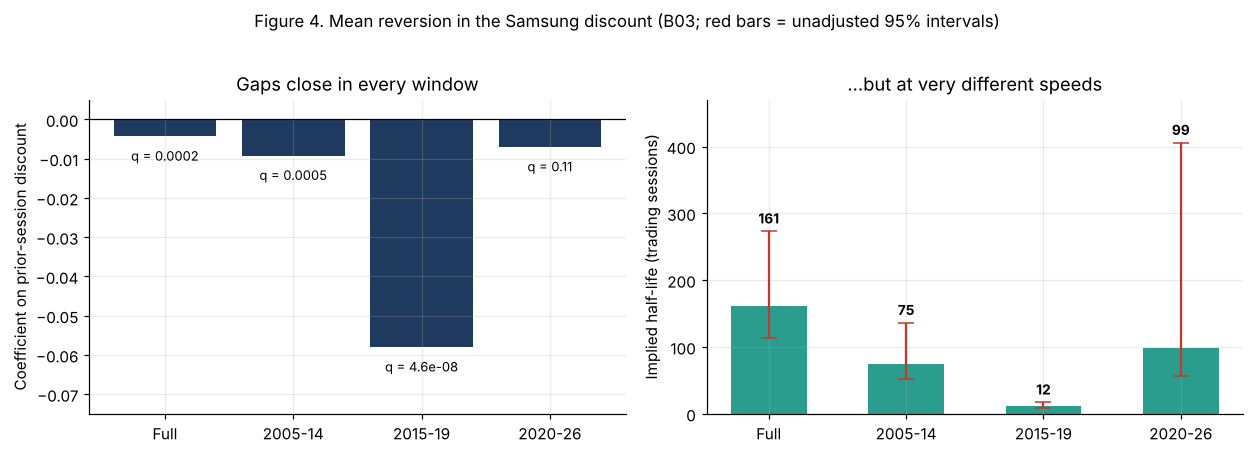

In [5]:
# B03 main sample: lag_discount coefficient and SE; BH q  (Nov 2 regression tables)
b03 = pd.DataFrame({"b": [-0.0043, -0.0092, -0.0580, -0.0070], "se": [0.0009, 0.0021, 0.0092, 0.0027],
                    "q": [0.0002, 0.0005, 4.57e-08, 0.1093]}, index=WINDOWS)
hl = lambda b: np.log(.5) / np.log(1 + b) if b < 0 else np.inf
b03["hl"] = b03.b.map(hl)
b03["hl_fast"] = (b03.b - 1.96 * b03.se).map(hl)     # unadjusted 95% interval ends
b03["hl_slow"] = (b03.b + 1.96 * b03.se).map(hl)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4))
a1.bar(WINDOWS, b03.b, color=NAVY)
for i, (c, q) in enumerate(zip(b03.b, b03.q)):
    a1.text(i, c - 0.003, f"q = {q:.2g}", ha="center", va="top", fontsize=8.5)
a1.axhline(0, color="black", lw=.8); a1.set_ylim(-0.075, 0.005)
a1.set_ylabel("Coefficient on prior-session discount"); a1.set_title("Gaps close in every window")

x = np.arange(4)
a2.bar(x, b03.hl, color=TEAL, width=.55)
a2.errorbar(x, b03.hl, yerr=[b03.hl - b03.hl_fast, b03.hl_slow - b03.hl], fmt="none", ecolor=RED, capsize=5)
for i, v in enumerate(b03.hl): a2.text(i, b03.hl_slow.iloc[i] + 12, f"{v:.0f}", ha="center", fontsize=9, fontweight="bold")
a2.set_xticks(x); a2.set_xticklabels(WINDOWS); a2.set_ylim(0, 470)
a2.set_ylabel("Implied half-life (trading sessions)"); a2.set_title("…but at very different speeds")
fig.suptitle("Figure 4. Mean reversion in the Samsung discount (B03; red bars = unadjusted 95% intervals)", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

### 4.4 A constant-cash interest-rate scenario did not carry forward

We carried a fixed cash proxy and a May 2021 calibration, unchanged, into January 2024 to September 2026, with three pre-declared pass-through assumptions and no fitted coefficient. The half pass-through version had looked good in an earlier selected window (4.58 points of error) but errs by about 25 points later, and zero pass-through actually wins on price error. All three paths also sit far below the observed September 2026 preferred price. This challenges this specific unchanged construction; it does not isolate a causal rate effect or refute every dividend mechanism.

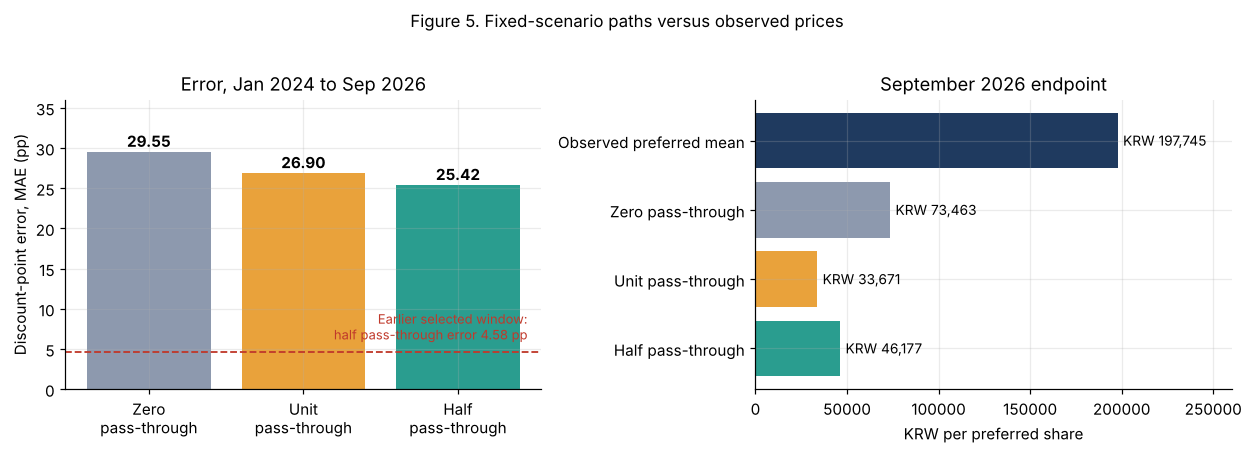

In [6]:
scen = pd.DataFrame({"Scenario": ["Zero\npass-through", "Unit\npass-through", "Half\npass-through"], "MAE": [29.55, 26.90, 25.42]})
endpoint = pd.Series({"Observed preferred mean": 197745, "Zero pass-through": 73463, "Unit pass-through": 33671, "Half pass-through": 46177})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4))
bars = a1.bar(scen.Scenario, scen.MAE, color=[GRAY, GOLD, TEAL])
a1.axhline(4.58, color=RED, ls="--", lw=1.2)
a1.text(2.45, 6.2, "Earlier selected window:\nhalf pass-through error 4.58 pp", ha="right", color=RED, fontsize=8.5)
for b in bars: a1.text(b.get_x() + b.get_width()/2, b.get_height() + .6, f"{b.get_height():.2f}", ha="center", fontweight="bold")
a1.set_ylim(0, 36); a1.set_ylabel("Discount-point error, MAE (pp)"); a1.set_title("Error, Jan 2024 to Sep 2026")

order = endpoint.index[::-1]
a2.barh(order, endpoint[order].values, color=[TEAL, GOLD, GRAY, NAVY])
for i, v in enumerate(endpoint[order].values): a2.text(v + 3000, i, f"KRW {v:,.0f}", va="center", fontsize=9)
a2.set_xlim(0, 260000); a2.set_xlabel("KRW per preferred share"); a2.set_title("September 2026 endpoint")
fig.suptitle("Figure 5. Fixed-scenario paths versus observed prices", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

*Conditional on vendor-source observations and retrospective rate inputs; 2025 to 2026 price levels have not been comparably issuer-qualified.*

## 5. Portfolio performance: what we can and cannot report

We cannot yet report estimated portfolio returns, volatility, Sharpe ratios, or drawdowns, for four reasons:

1. **No validated fair-discount model.** Historical medians and persistence are benchmarks, not fair value.
2. **The regressions are not trading signals.** They are retrospective and explain under 4% of daily variation.
3. **Executability is unestablished.** We have not yet pinned down trade clocks, borrow and conversion constraints, or transaction costs for any pair (TSMC and Berkshire are the clearest examples).
4. **A long-horizon specification job has an unobserved result.** The remote run was interrupted, so we do not use or cite it.

Producing a backtest now would mean inventing returns, so we show our pipeline instead. The repository we build on, a fork of BYU Silver Fund's `sf-quant`, already includes walk-forward backtesting and performance tools covering returns, leverage, drawdowns, turnover, and information coefficients. We have not yet run it on our own signals.

| Step | Requirement |
|---|---|
| Signal | Built only from information available at each forecast origin, with dated cash expectations |
| Comparators | Persistence and a trailing median, kept as serious benchmarks |
| Validation | Walk-forward, out-of-sample, with predeclared specifications |
| Execution | Realistic trade clocks, conversion and borrow constraints, and costs |
| Metrics | Annualized return and volatility, Sharpe ratio, maximum drawdown, turnover, information coefficient |

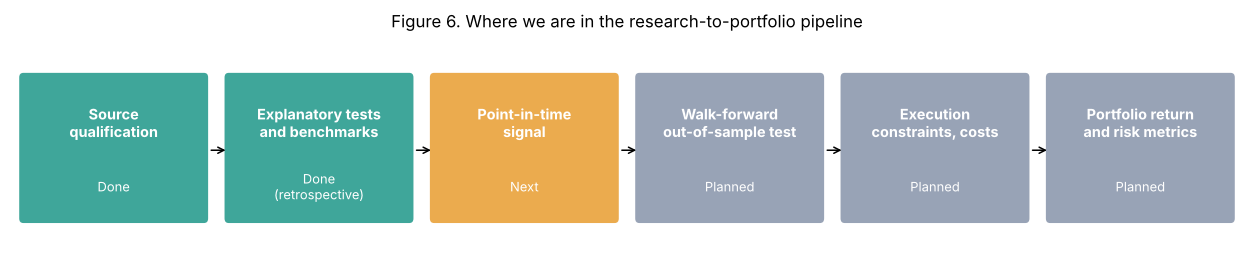

In [7]:
steps = [("Source\nqualification", "Done", TEAL),
         ("Explanatory tests\nand benchmarks", "Done\n(retrospective)", TEAL),
         ("Point-in-time\nsignal", "Next", GOLD),
         ("Walk-forward\nout-of-sample test", "Planned", GRAY),
         ("Execution\nconstraints, costs", "Planned", GRAY),
         ("Portfolio return\nand risk metrics", "Planned", GRAY)]
fig, ax = plt.subplots(figsize=(11.5, 2.6)); ax.axis("off"); ax.set_xlim(0, 6); ax.set_ylim(0, 1)
for i, (name, status, c) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((i + .06, .2), .88, .62, boxstyle="round,pad=0.02", fc=c, ec="none", alpha=.9))
    ax.text(i + .5, .62, name, ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
    ax.text(i + .5, .34, status, ha="center", va="center", color="white", fontsize=8.5)
    if i < 5: ax.annotate("", xy=(i + 1.06, .5), xytext=(i + .96, .5), arrowprops=dict(arrowstyle="->", color="black"))
ax.set_title("Figure 6. Where we are in the research-to-portfolio pipeline", fontsize=11)
plt.tight_layout(); plt.show()

## 6. Breadth: other cases and screening registry

Each additional case needs its own economic and accounting framework: a full-portfolio NAV discount, an operating insurer's stake, different voting classes, and an ADR conversion are not interchangeable ratios. Our consolidated registry holds **114 screening records** (screens, not completed studies; some overlap or are parked). Five cases are next in line.

| Case | What still needs to be done |
|---|---|
| Samsung common / preferred | Economic model using only information available at each origin; keep persistence as comparator |
| Prosus / Tencent | Reconcile 2023 structure, NAV denominator, and publication dates |
| SK Square / SK Hynix | Reconcile share counts, treasury treatment, and valuation dates |
| Samsung Fire / Samsung Electronics | Model insurance operations and both parent classes without double-counting |
| TSMC local / ADR | Reconstruct conversion regimes and usable trade clocks |

Two further results shaped our caution. For **Svolder** (NAV versus share price), conclusions depend on how the target is built: a last-observation monthly target favors the median, while a source-month mean and two fixed ten-year anchors favor persistence. For **Berkshire**, all 764 negative normalized close observations have touching or overlapping daily ranges, which permits a timing explanation but does not show the gap was tradable.

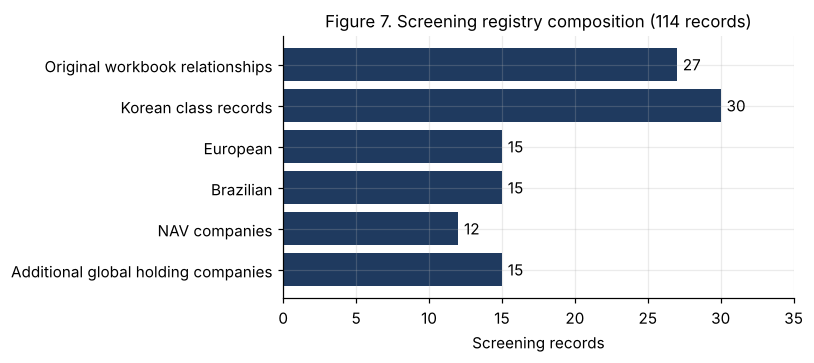

In [8]:
registry = pd.Series({"Original workbook relationships": 27, "Korean class records": 30, "European": 15,
                      "Brazilian": 15, "NAV companies": 12, "Additional global holding companies": 15})
assert registry.sum() == 114
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.barh(registry.index[::-1], registry.values[::-1], color=NAVY)
for b in bars: ax.text(b.get_width() + .4, b.get_y() + b.get_height()/2, int(b.get_width()), va="center")
ax.set_xlim(0, 35); ax.set_xlabel("Screening records")
ax.set_title("Figure 7. Screening registry composition (114 records)", fontsize=11)
plt.tight_layout(); plt.show()

## 7. Conclusions, limitations, and next steps

**What we can say.** Samsung's preferred discount is not explained by issued-share supply or a constant-cash story alone. Korean preferred discounts move together across a selected universe. Persistence is a hard benchmark to beat. Daily US factor returns explain very little and mostly do not survive multiple-testing correction. The discount's own mean reversion is the most reliable pattern we found, and it is fastest in 2015 to 2019. International cases show that accounting, timing, conversion rights, and share-count definitions can create or remove apparent gaps.

**What we cannot say.** We have not validated a fair-discount model, an out-of-sample signal, or a tradable strategy.

**Limitations.** Regressions are retrospective, use a retrospective US-session alignment, and cover only the Samsung pair. Scenario results rely on vendor data and retrospective rate inputs. Peer counts use different denominators in a selected universe. Svolder results are qualitative here.

**Next steps.** (1) Build a point-in-time mean-reversion signal and test it walk-forward against persistence, starting from the 2015 to 2019 pattern. (2) Run the repository's backtest and performance tools on that signal to produce return and risk metrics. (3) Complete the Svolder FY2024/25 NAV reconciliation and advance the GBL source gates. (4) Keep inaccessible or irreconcilable candidates parked.

## Sources and reproducibility

Figures 1, 5, and 7 use numbers from our November 6 internal research report and team notes (Figure 1 ownership from team notes). Figures 2 to 4 use the B01 to B04 coefficient and diagnostic tables circulated November 2, 2026; p-values in Figure 3 are recomputed from those coefficients and standard errors under the stated normal approximation, and half-lives and their intervals in Figure 4 are arithmetic from the B03 coefficients. No chart is a new empirical test or a simulated series. Run all cells top to bottom with Python 3, `numpy`, `pandas`, `scipy`, and `matplotlib`; no data files are needed. Repository: https://github.com/benpinoli/MRP-Project